# QuaRK: A Quantum Reservoir Kernel for Time Series Learning — reproduction notebook

**The paper:** QuaRK is a quantum reservoir for time series designed to scale, with guarantees that it can fit any set of windows and generalizes on weakly dependent series.

QuaRK feeds each window, one time step at a time, into 3 random 5-qubit circuits (sub-reservoirs) that are never trained, estimates 105 Pauli averages on each (315 features) from measurement shots, and trains only a Matérn kernel ridge on them.

**This reproduction:**
1. The paper's experiments reproduce exactly, and its learning claims hold qualitatively.
2. On the paper's synthetic tasks, simple classical models reach a lower test error than QuaRK.
3. At equal measurement budget, the paper's classical shadows beat the noise model its code simulated.
4. A photonic version of the reservoir matches QuaRK, with or without photon interference.

Paper: [arXiv:2602.13531](https://arxiv.org/abs/2602.13531); code: [abdo-aary/quark](https://github.com/abdo-aary/quark), paper-era commit `8f02ff1`, which drew the paper's figures. The authors' later code (commit `c8cf7b6`) extends the paper with genuine classical shadows, an echo-state-network comparison on 10 real datasets and a validation-based protocol; we say where it addresses a point. Our deviations are in the README.

Each section recomputes its numbers from the stored results in `results/` (100 runs, regenerated by `utils/make_results.py`); section 2 also reruns its comparison at reduced size (about 15 s in all). Checks with known answers (circuit against closed-form reset, features against the authors' release, MerLin against permanents) are unit tests.

**Metric:** test MSE on 2,000 held-out windows divided by the test-label variance, mean over 5 seeds (12345 is the authors' dataset). The windows come from a synthetic 3-dimensional VARMA process (App. B), with the paper's three labels (App. B.2): current-point readout (F1; a single-step forecast in the paper's text, the window's last point in its code), exponential fading (F2) and Volterra (F3). "Beats" means lower in a seed-by-seed comparison (difference beyond twice its standard error, a rule fixed before the runs).

In [1]:
import json
import sys
import tempfile
from pathlib import Path

from IPython.display import Image, Markdown, display

PAPER = Path.cwd()
assert (PAPER / "lib" / "runner.py").is_file(), "run this notebook from papers/QuaRK"
# The repository root (runtime_lib), papers/ (the QuaRK package) and utils/.
sys.path[:0] = [str(PAPER.parents[1]), str(PAPER.parent), str(PAPER / "utils")]
from report_statistics import describe, paired  # noqa: E402

from QuaRK.lib.runner import train_and_evaluate  # noqa: E402
from runtime_lib.config import deep_update, load_config  # noqa: E402
from runtime_lib.dtypes import resolve_config_dtypes  # noqa: E402

RESULTS = PAPER / "results"
STORED = {
    name: json.loads((RESULTS / f"{name}.json").read_text())
    for name in ("result_tables", "release_comparison", "statistics")
}
TASKS = {"current_point_readout": "F1", "exp_fading": "F2", "volterra": "F3"}
CANDIDATES = {
    candidate["candidate"]: candidate
    for sweep in STORED["result_tables"]["sweeps"].values()
    for candidate in sweep["candidates"]
}


def values(candidate, task, key="mse_test"):
    """Per-seed value of a stored metric (ridge chosen on validation data)."""
    return {
        int(seed): run["tasks"][task][key]
        for seed, run in CANDIDATES[candidate]["per_seed"].items()
    }


def mean_normalized(candidate, task):
    return describe(values(candidate, task, "normalized_mse_test").values())["mean"]


def verdict(a, b, task):
    """The rule fixed before the runs, on the test MSE, and the seeds where ``a`` is lower."""
    p = paired(values(a, task), values(b, task), "first", "second")
    return p["label"], p["a_lower_seeds"], len(p["seeds"])


def beats(a, b, task):
    label, a_lower, seeds = verdict(a, b, task)
    return label == "first lower" and a_lower == seeds


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. The paper's experiments reproduce exactly, and its learning claims hold qualitatively

At the authors' seed, our values match their released values within a relative 1.5·10⁻⁹ (computed below).

**Look at:** the crosses (the authors' released values) sit on our curves. Fit examples (paper Fig. 4): [figure](results/fig4_fit_examples.png).

Largest relative difference with the authors' released values: 1.45e-09


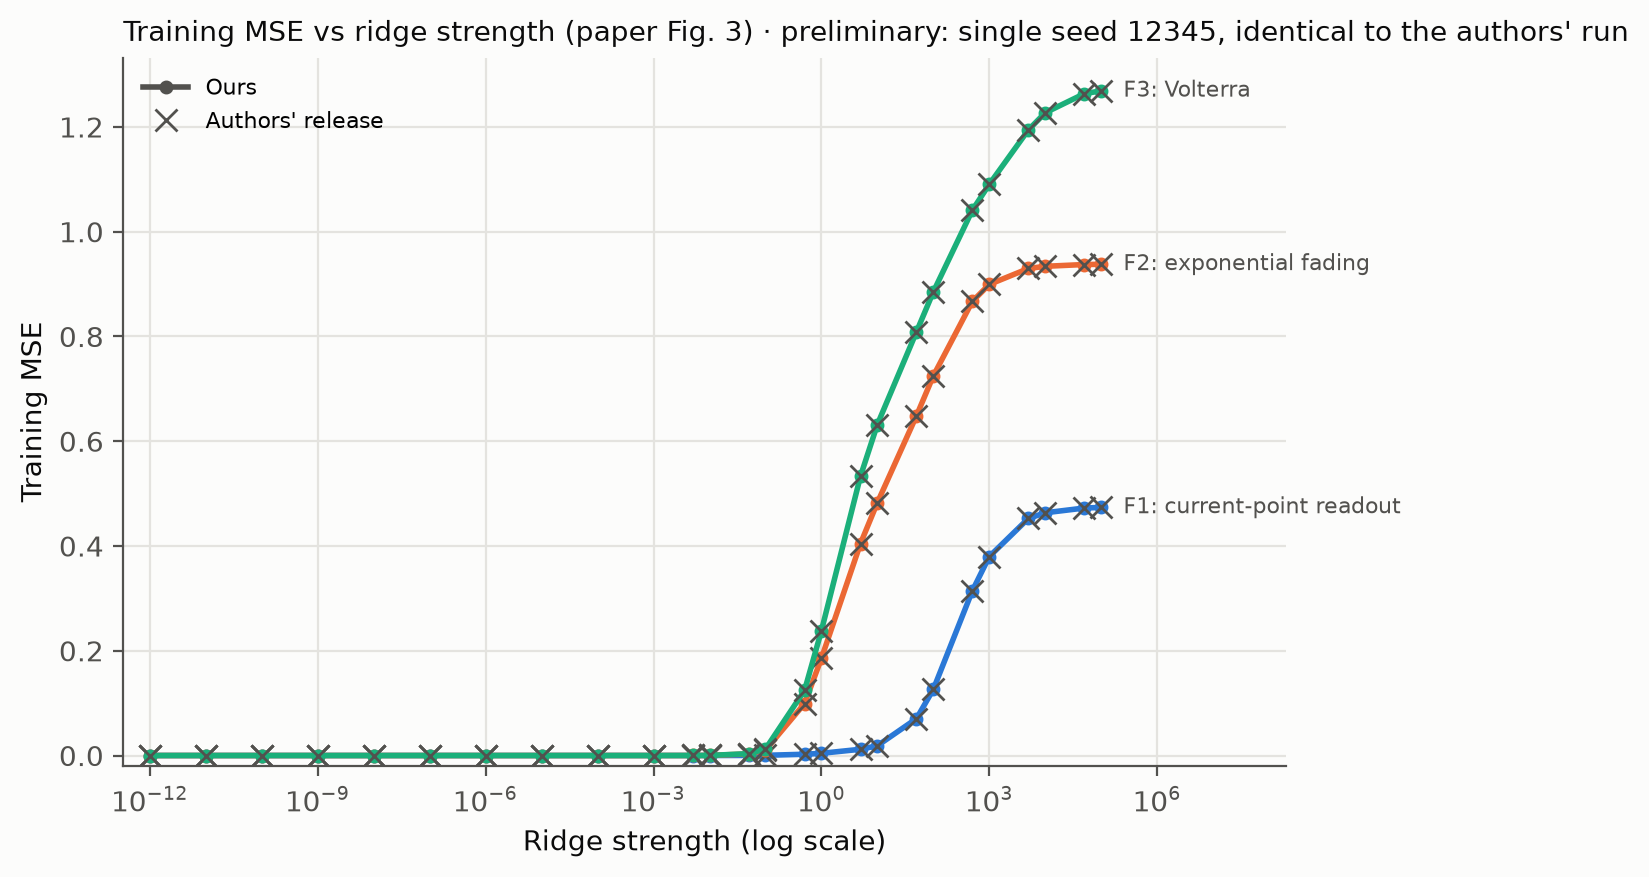

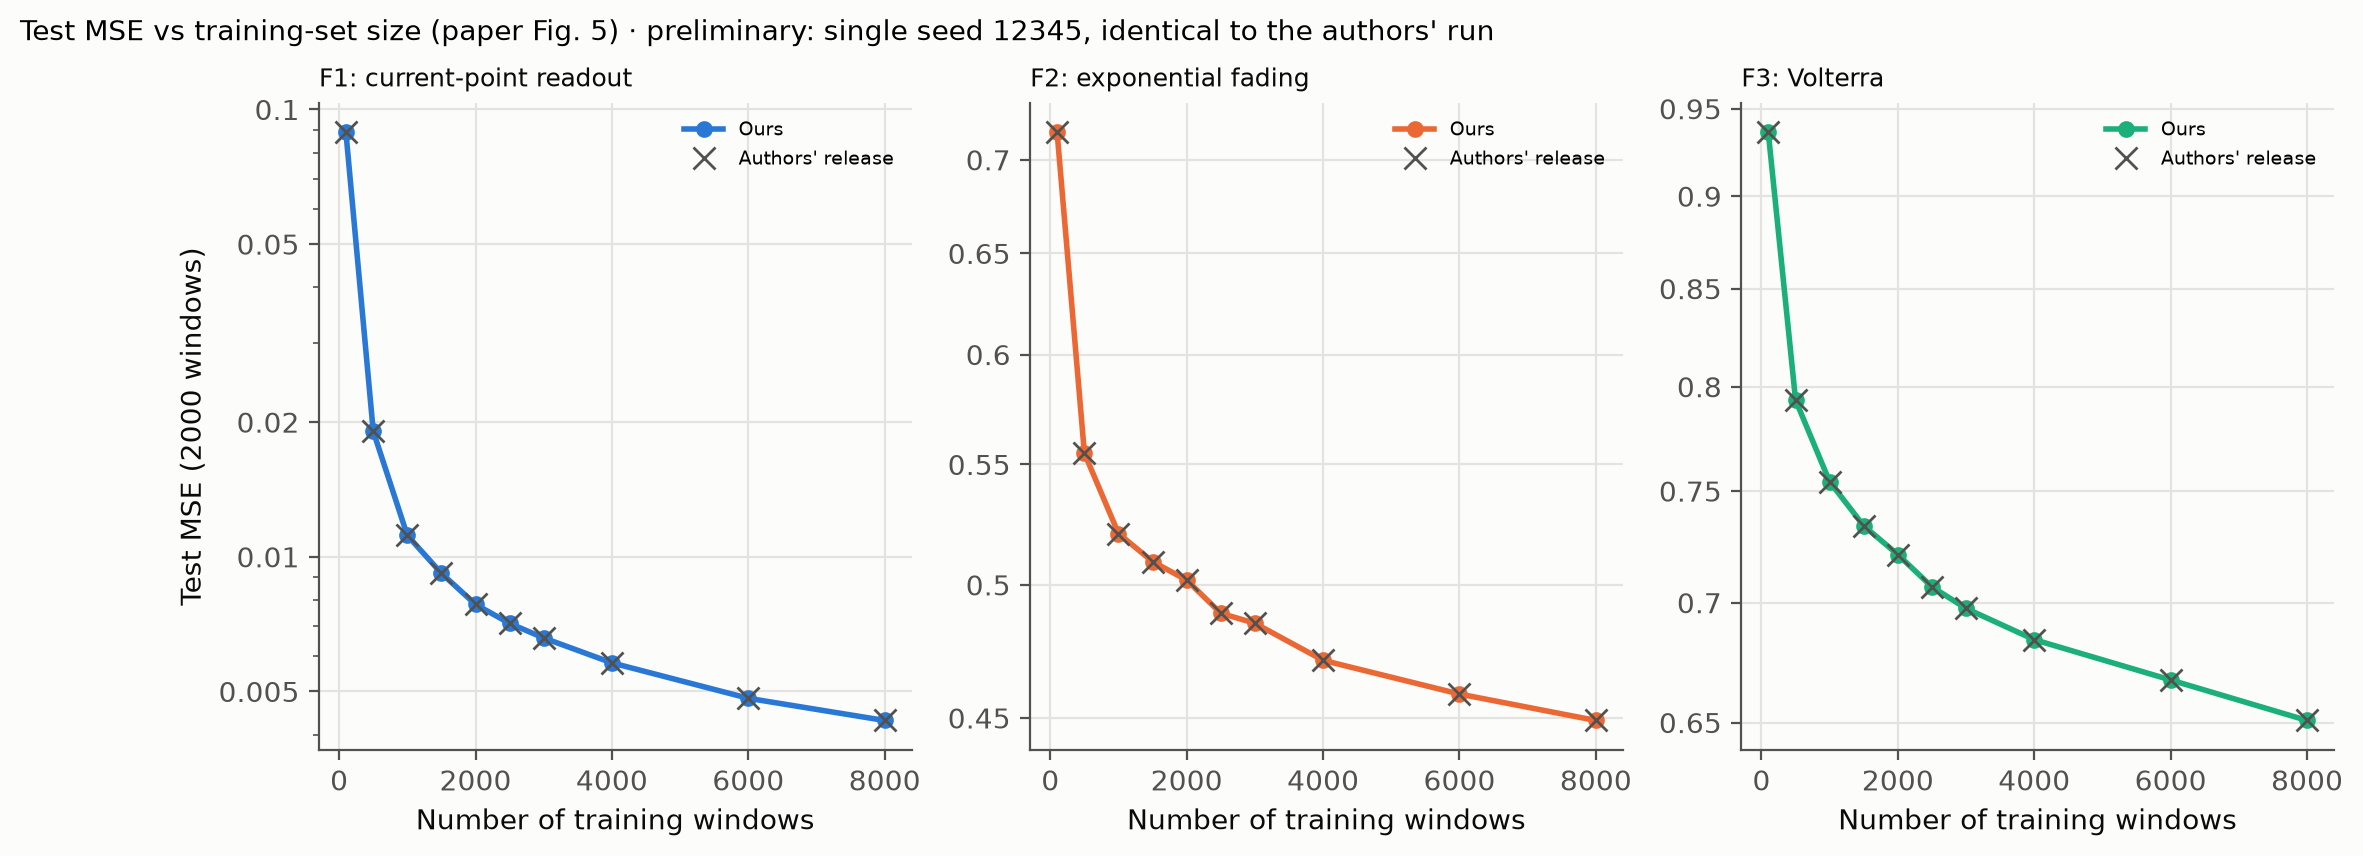

In [2]:
release = STORED["release_comparison"]["tasks"]
release_gap = max(
    release[task][key]
    for task in TASKS
    for key in (
        "xi_relative_difference",
        "fig3_training_mse_max_relative_difference_above_rounding_level",
        "fig3_test_mse_max_relative_difference",
        "fig5_test_mse_max_relative_difference",
    )
)
print(f"Largest relative difference with the authors' released values: {release_gap:.2e}")
# Paper Figs. 3 and 5, our curves with the authors' released values as crosses.
for figure in ("fig3_regularization_sweep", "fig5_training_size_sweep"):
    display(Image(filename=str(RESULTS / f"{figure}.png")))


Over 5 seeds, **look at:** each claim against what we measure.

In [3]:
classical_kernels = ("raw_window_kernel", "esn_default", "esn_tuned")
training_mse = {
    c: max(max(values(c, t, "mse_train_at_smallest_reg").values()) for t in TASKS)
    for c in ("quark", *classical_kernels)
}
decay = {
    d["task"]: d
    for d in STORED["statistics"]["decay"]
    if d["candidate"] == "quark" and d["task"] in TASKS
}
bound = {
    b["task"]: b["min_ratio_partial_to_gap"]
    for b in STORED["statistics"]["bound"]["paper_settings"]
}
table(
    ["Paper's claim", "What we measure"],
    [
        [
            "Training error reaches zero (Figs. 3–4)",
            f"training MSE at the weakest ridge, at most: QuaRK {training_mse['quark']:.0e}; "
            f"classical kernel models {max(training_mse[c] for c in classical_kernels):.0e}",
        ],
        [
            "Test error falls like 1/√N, a slope of −0.5 (Fig. 5)",
            "steps of N where it falls, over the seeds: "
            + ", ".join(
                f"{TASKS[t]} {d['decreasing_steps']}/{d['total_steps']}"
                for t, d in decay.items()
            )
            + "; slope of log test MSE against log N (95 % interval): "
            + "; ".join(
                f"{TASKS[t]} {d['slope']['mean']:.2f} ({d['slope']['ci95'][0]:.2f} to {d['slope']['ci95'][1]:.2f})"
                for t, d in decay.items()
            ),
        ],
        [
            "Generalization bound (Theorem 2)",
            "bound divided by the measured gap, at least: "
            + "; ".join(f"{TASKS[t]} {bound[t]:,.0f}" for t in TASKS),
        ],
    ],
)

| Paper's claim | What we measure |
|---|---|
| Training error reaches zero (Figs. 3–4) | training MSE at the weakest ridge, at most: QuaRK 6e-21; classical kernel models 9e-13 |
| Test error falls like 1/√N, a slope of −0.5 (Fig. 5) | steps of N where it falls, over the seeds: F1 45/45, F2 45/45, F3 45/45; slope of log test MSE against log N (95 % interval): F1 -0.46 (-0.55 to -0.37); F2 -0.09 (-0.12 to -0.07); F3 -0.09 (-0.11 to -0.06) |
| Generalization bound (Theorem 2) | bound divided by the measured gap, at least: F1 6,605; F2 1,733; F3 1,427 |

**Result:** the paper's figures are exact; its claims hold in direction, not in their quantitative form. Every kernel model reaches zero training error, classical ones included; the error falls like 1/√N on F1 only; the bound is too loose to be tested.

## 2. On the paper's synthetic tasks, simple classical models reach a lower test error than QuaRK

The paper has no baseline on these tasks; ours use the same windows, split, seeds and tuning on validation data.

**Look at:** the top blue row (QuaRK, paper settings) sits to the right of every orange row (classical) on all three tasks, and every blue row does on F2 and F3; log axis, lower is better.

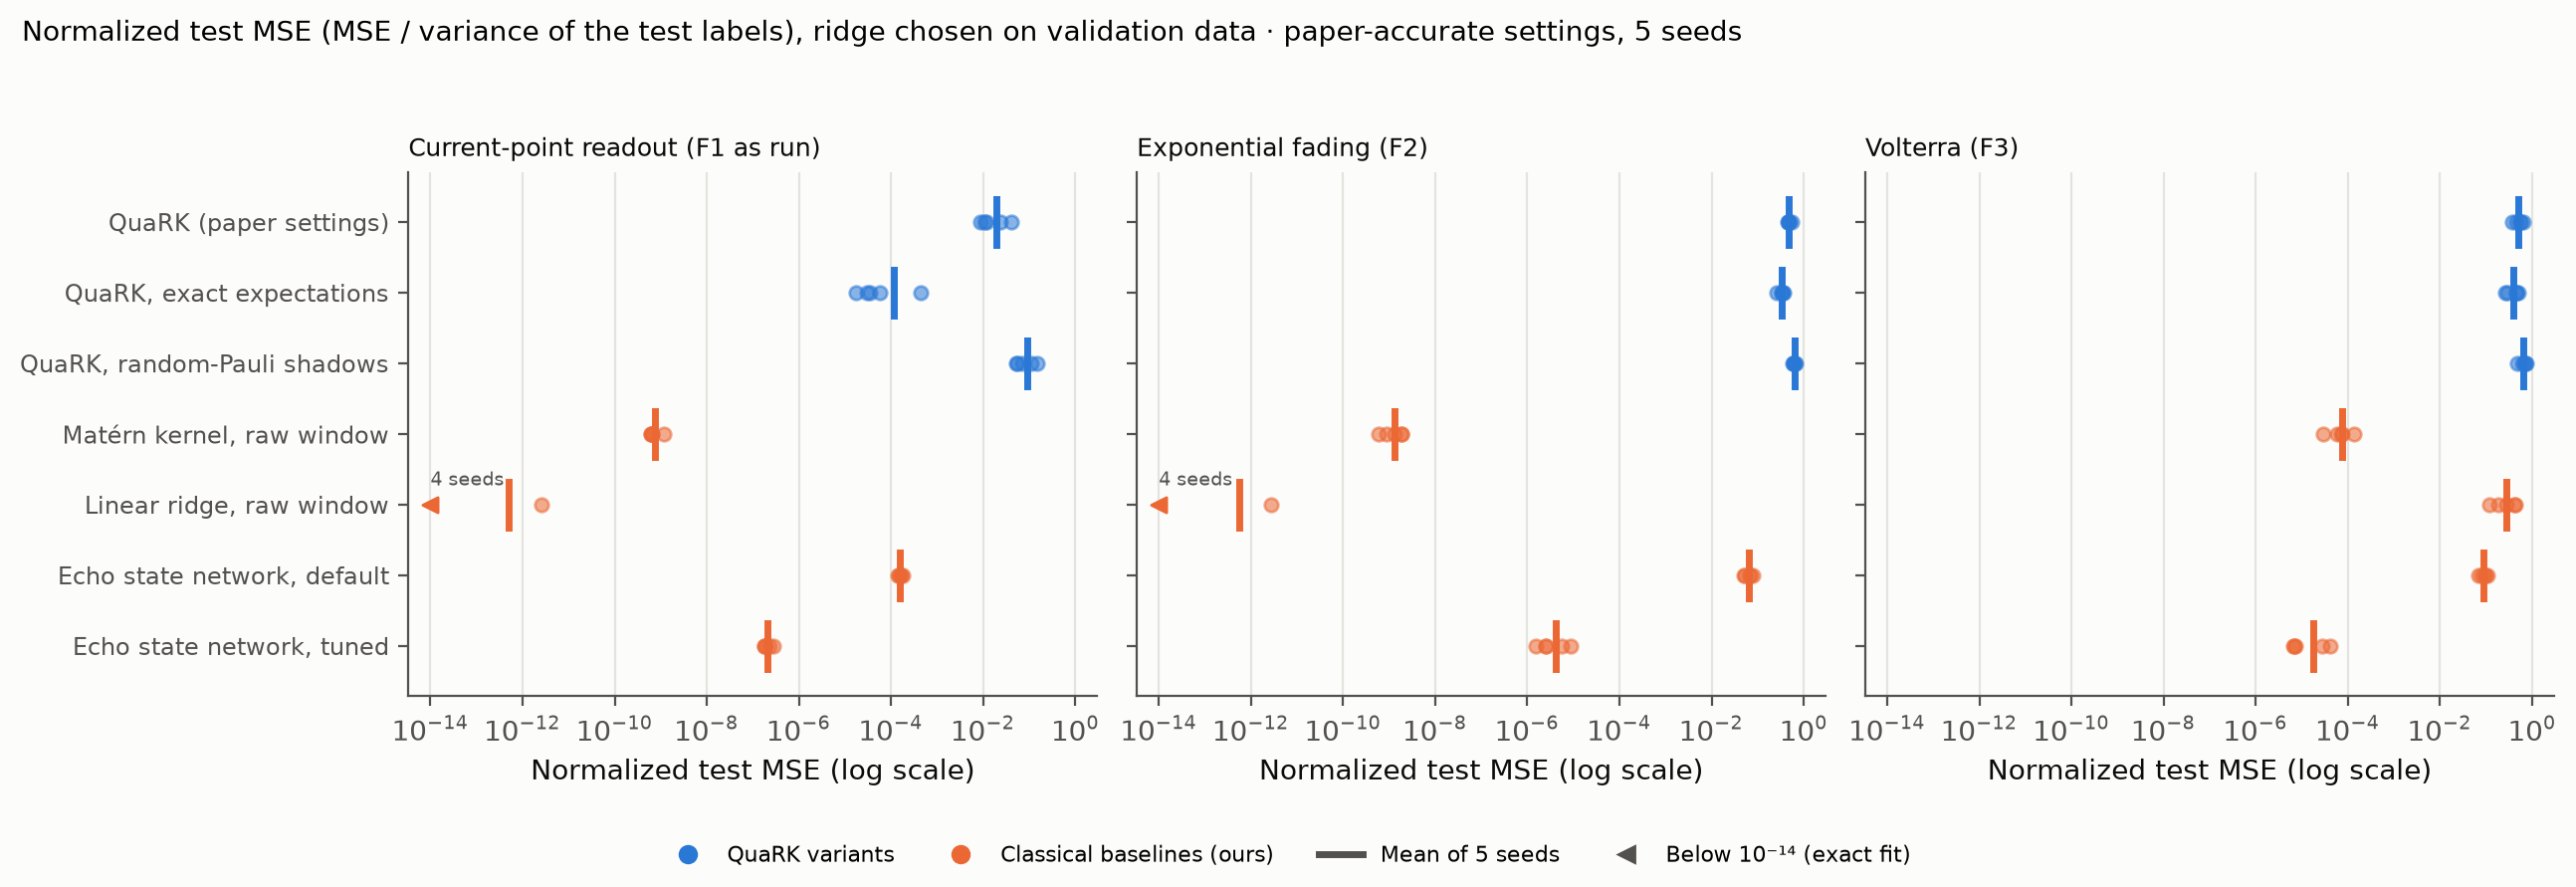

Baseline-task pairs where the baseline beats QuaRK in 5 of 5 seeds: 12 of 12
The same against QuaRK without shot noise, on F2 and F3: 8 of 8
F2, mean normalized test MSE: untuned echo state network (315 features) 0.063, QuaRK 0.48


In [4]:
display(Image(filename=str(RESULTS / "model_comparison.png")))
baselines = ("raw_window_kernel", "raw_window_linear", "esn_default", "esn_tuned")
print(
    "Baseline-task pairs where the baseline beats QuaRK in 5 of 5 seeds:",
    sum(beats(b, "quark", t) for b in baselines for t in TASKS),
    "of",
    len(baselines) * len(TASKS),
)
print(
    "The same against QuaRK without shot noise, on F2 and F3:",
    sum(
        beats(b, "quark_exact", t)
        for b in baselines
        for t in ("exp_fading", "volterra")
    ),
    "of",
    2 * len(baselines),
)
print(
    "F2, mean normalized test MSE: untuned echo state network (315 features) "
    f"{mean_normalized('esn_default', 'exp_fading'):.3f}, QuaRK {mean_normalized('quark', 'exp_fading'):.2f}"
)

Run it yourself: the same comparison at reduced size (1,000 windows, one seed, about 10 s). It illustrates the pipeline; the evidence is the 5-seed figure above.

In [5]:
LIVE = {
    "QuaRK (paper settings)": "quark_original.json",
    "Echo state network, default": "esn_default_classical.json",
    "Matérn kernel on the raw window": "raw_window_kernel_classical.json",
}
live_tasks = ["exp_fading", "volterra"]
live_rows = []
for name, overlay in LIVE.items():
    # Defaults, then the model's config, then the reduced size, as the runtime merges them.
    cfg = deep_update(
        load_config(PAPER / "configs" / "defaults.json"),
        load_config(PAPER / "configs" / overlay),
    )
    cfg["seed"] = 12345
    cfg["data"].update(num_windows=1000, check_release=False, tasks=live_tasks)
    cfg["outputs"]["save_features"] = False
    with tempfile.TemporaryDirectory() as run_dir:  # nothing is written under outdir/
        train_and_evaluate(resolve_config_dtypes(cfg), Path(run_dir))
        tasks = json.loads((Path(run_dir) / "metrics.json").read_text())["tasks"]
    live_rows.append(
        [name]
        + [
            f"{tasks[t]['selections']['validation']['normalized_mse_test']:.2g}"
            for t in live_tasks
        ]
    )
table(["1,000 windows, seed 12345, normalized test MSE", "F2", "F3"], live_rows)

| 1,000 windows, seed 12345, normalized test MSE | F2 | F3 |
|---|---|---|
| QuaRK (paper settings) | 0.62 | 0.63 |
| Echo state network, default | 0.077 | 0.18 |
| Matérn kernel on the raw window | 1.7e-08 | 0.23 |

**Result:** every classical baseline beats QuaRK on every task, in 5 of 5 seeds. Even a random classical reservoir with QuaRK's 315 features and readout does (0.063 against 0.48 on F2), and shot noise is not the reason: without it, QuaRK still trails on F2 and F3 (a check added after the runs). On real data, the authors' later comparison is mixed (QuaRK better on 5 of 10 datasets).

## 3. At equal measurement budget, the paper's classical shadows beat the noise model its code simulated

The code gives each of the 105 observables its own shots; the paper's text shares snapshots among all of them.

**Look at:** at the same number of measurements (x-axis), orange (shadows, as in the paper's text) lies below blue (the code's model). The y-axis is the error with shot noise divided by the error without.

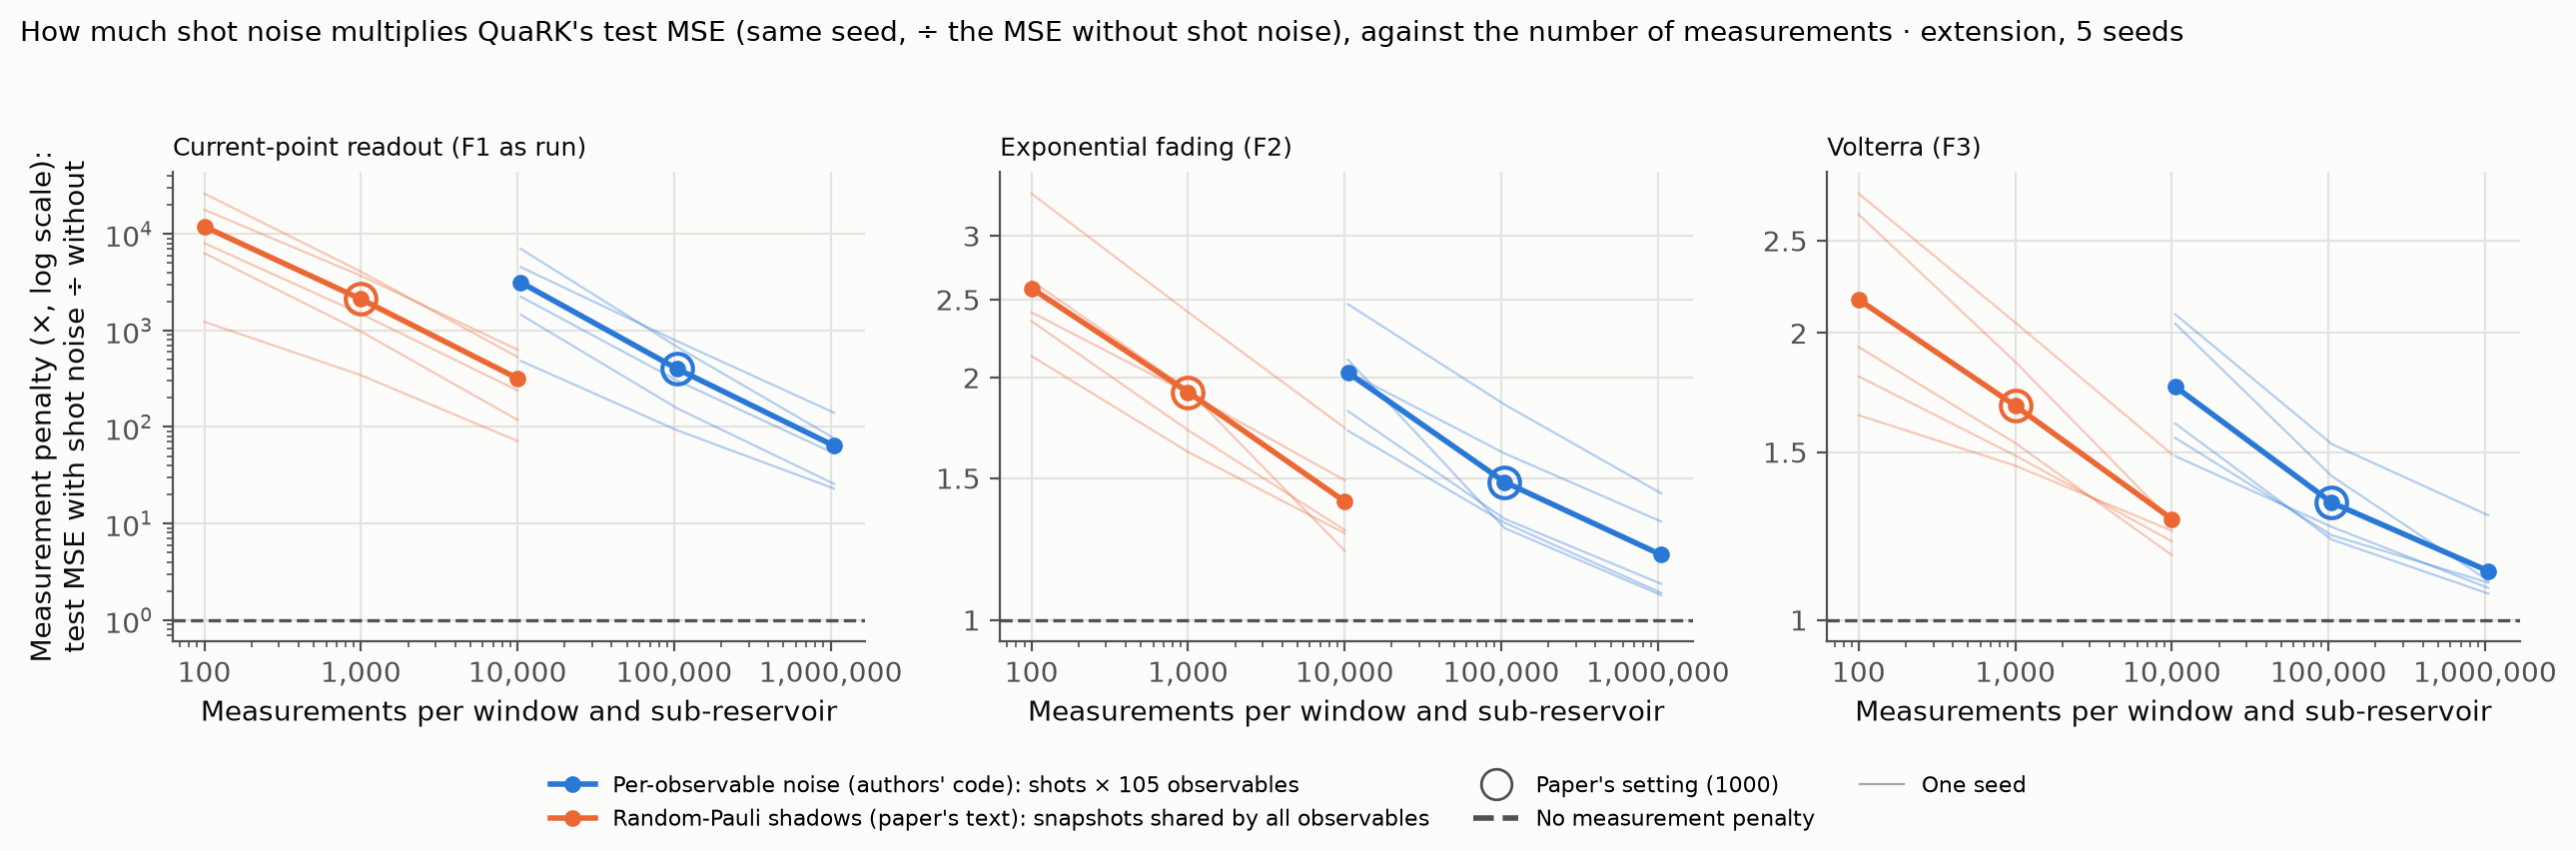

F1: shadows lower, 5/5 seeds
F2: shadows lower, 5/5 seeds
F3: shadows lower, 5/5 seeds


In [6]:
display(Image(filename=str(RESULTS / "shot_budget.png")))
# About 10^4 measurements each: 10,000 shadows against 100 shots on each of 105 observables.
for task, short in TASKS.items():
    label, shadows_lower, seeds = verdict(
        "quark_shadows_shots_10000", "quark_shots_100", task
    )
    winner = {"first lower": "shadows lower", "second lower": "code's model lower"}
    print(f"{short}: {winner.get(label, label)}, {shadows_lower}/{seeds} seeds")

**Result:** at about 10⁴ measurements, shadows beat the code's model on every task, in 5 of 5 seeds. The paper's figures used the code's model, which spends 105 times more measurements than the text's 1000 shadows; the authors' later code adopts shadows.

## 4. A photonic version of the reservoir matches QuaRK, with or without photon interference

Per sub-reservoir, 3 photons in 14 modes in MerLin, with QuaRK's reset, readout and data, and ideal components; a control makes the photons distinguishable, so they cannot interfere (`docs/photonic_adaptation.md`).

**Look at:** the three columns, mean normalized test MSE, all without shot noise.

In [7]:
columns = {
    "QuaRK, exact": "quark_exact",
    "Photonic, exact": "quark_exact_merlin",
    "Photonic, no interference": "quark_distinguishable_merlin",
}
table(
    ["Task", *columns],
    [
        [short, *(f"{mean_normalized(c, task):.3g}" for c in columns.values())]
        for task, short in TASKS.items()
    ],
)
names = {candidate: column for column, candidate in columns.items()}
for a, b in (
    ("quark_exact_merlin", "quark_exact"),
    ("quark_exact_merlin", "quark_distinguishable_merlin"),
):
    print(
        f"{names[a]} against {names[b]}, F1 / F2 / F3:",
        " / ".join(verdict(a, b, t)[0] for t in TASKS),
    )
print(
    "Largest effect of switching interference off:",
    f"{max(abs(mean_normalized('quark_exact_merlin', t) - mean_normalized('quark_distinguishable_merlin', t)) for t in TASKS):.3g}",
)

| Task | QuaRK, exact | Photonic, exact | Photonic, no interference |
|---|---|---|---|
| F1 | 0.000116 | 0.000143 | 0.00014 |
| F2 | 0.328 | 0.307 | 0.307 |
| F3 | 0.391 | 0.388 | 0.387 |

Photonic, exact against QuaRK, exact, F1 / F2 / F3: no clear separation / no clear separation / no clear separation
Photonic, exact against Photonic, no interference, F1 / F2 / F3: no clear separation / no clear separation / no clear separation
Largest effect of switching interference off: 0.00102


**Result:** the photonic reservoir matches QuaRK, and switching interference off changes nothing (means differ by at most 0.00102). Our reading: the accuracy comes from the nonlinear encoding and the fading memory, not from interference.

## Conclusion

1. The paper's experiments reproduce exactly, and its learning claims hold qualitatively.
2. On the paper's synthetic tasks, simple classical models reach a lower test error than QuaRK.
3. At equal measurement budget, the paper's classical shadows beat the noise model its code simulated.
4. A photonic version of the reservoir matches QuaRK, with or without photon interference.

**Limitations:** synthetic data with 3 input dimensions, as in the paper, so the projection never reduces the dimension and the scalability argument is not tested; Theorem 2 is checked numerically, not its proof.